# Diffuse foreground-dominated dataset at z = 7.391

> **Research project:** Unsupervised image segmentation of ionized regions in simulated 21-cm tomographic data during the Epoch of Reionization (EoR).

## Notebook purpose

Uses SKA_AA4_TRECS-Diffuse_2HR_10S_z_7.391_cube.fits and includes entropy, Gaussian/FFT processing, thresholding, histograms and watershed experiments.

## Research context

The experiments investigate image-processing approaches for identifying candidate ionized (H II) structures in 21-cm brightness-temperature slices. The work compares local-entropy enhancement, unsharp masking, Gaussian smoothing, Fourier-domain low-pass filtering, local thresholding, morphological cleanup and watershed-based region partitioning.

## How to use this notebook

1. Run in Google Colab or a local Jupyter environment.
2. Install the packages listed in `requirements.txt`.
3. Obtain the FITS input dataset(s) described in `docs/datasets.md` and update file paths where needed.
4. Run cells in order. Some cells reuse variables created earlier in the notebook.
5. Treat displayed masks as algorithm outputs; physical interpretation requires checking the mask convention and, where available, comparison with simulation truth.

## Reproducibility notes

- Original code cells and saved outputs are retained in this annotated copy.
- The original downloaded notebook is preserved under `archive/originals/`.
- This notebook has not been represented as independently validated or fully reproducible; file paths, array shapes, parameter choices and execution order should be checked before rerunning.

---


### Unsharp masking
Enhance local edges by adding a scaled high-frequency residual to a smoothed image. Inspect the `radius` and `amount` settings because sharpening can amplify noise and create halos.


In [ ]:
from astropy.io import fits
import matplotlib.pyplot as plt
import numpy as np
from skimage.filters.rank import entropy
from skimage.morphology import disk
from skimage import exposure
from skimage.util import img_as_ubyte
from skimage import data
from skimage.filters import unsharp_mask
from skimage import filters as ski
from skimage import filters, exposure, morphology


In [ ]:
from google.colab import  files
uploaded = files.upload()

Saving SKA_AA4_TRECS-Diffuse_2HR_10S_z_7.391_cube.fits to SKA_AA4_TRECS-Diffuse_2HR_10S_z_7.391_cube.fits


### Input data: FITS loading
Load the FITS file and inspect/extract the data array. Confirm the HDU, axis order, selected slice index and resulting 2-D shape before interpreting the image.


Cube shape: (256, 202, 202)
Slice shape: (202, 202)


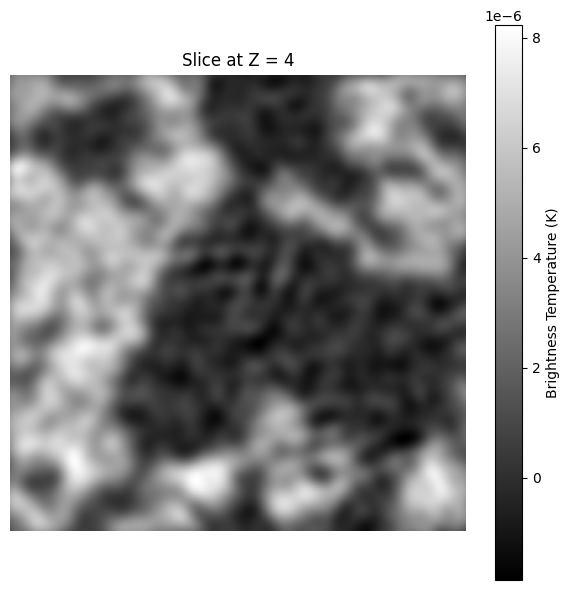

In [ ]:

from astropy.io import fits
import matplotlib.pyplot as plt
import numpy as np

# Load the FITS cube
hdul2 = fits.open('SKA_AA4_TRECS-Diffuse_2HR_10S_z_7.391_cube.fits')
cosmo_data2 = np.squeeze(hdul2[0].data)  # Shape should be (X, Y, Z)
print("Cube shape:", cosmo_data2.shape)

# Choose the Z index (redshift/frequency slice)
z_index = 4

 # 🔁 Change this to whatever slice you want (0 to max)

# Extract the 2D slice
cosmo_1 = cosmo_data2[z_index, :, :]
print("Slice shape:", cosmo_1.shape)

# Plot the slice
plt.figure(figsize=(6, 6))
plt.imshow(cosmo_1, cmap='grey')
plt.title(f"Slice at Z = {z_index}")
plt.colorbar(label='Brightness Temperature (K)')
plt.axis('off')
plt.tight_layout()
plt.show()


In [ ]:
cosmo_data2.shape

(256, 202, 202)

### Local entropy enhancement
Calculate neighbourhood entropy using a disk-shaped footprint. This measures local texture/variation, not ionization directly; intensity rescaling and footprint radius affect the result.


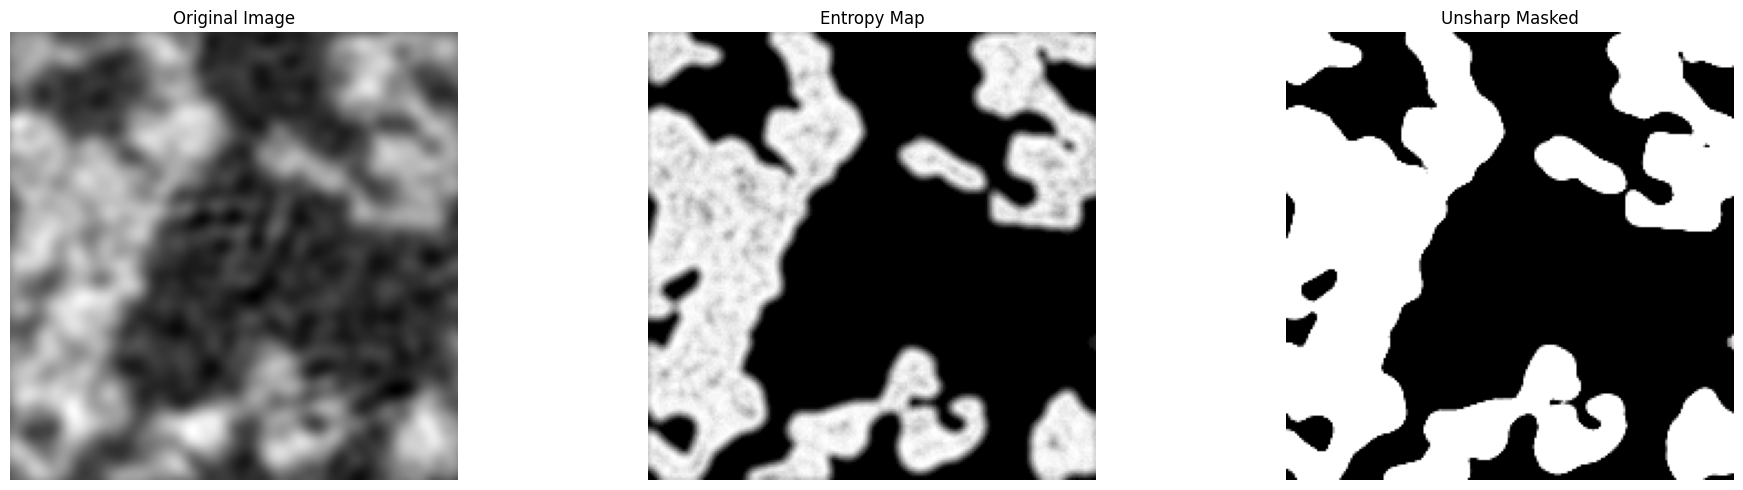

In [ ]:
image1 = cosmo_1  # Dummy brightness temperature map

# --- 2. Apply Local Entropy ---
entropy_input = img_as_ubyte(exposure.rescale_intensity(cosmo_1))
entropy_map1 = entropy(entropy_input, morphology.disk(3))

# --- 3. Apply Unsharp Masking to sharpen edges ---
sharpened1 = unsharp_mask(entropy_map1, radius=20, amount=1)

fig, axes = plt.subplots(1, 3, figsize=(20, 5))

axes[0].imshow(image1, cmap='gray')
axes[0].set_title("Original Image")
axes[0].axis('off')

axes[1].imshow(entropy_map1, cmap='gray')
axes[1].set_title("Entropy Map")
axes[1].axis('off')

axes[2].imshow(sharpened1, cmap='gray')
axes[2].set_title("Unsharp Masked")
axes[2].axis('off')

plt.tight_layout()
plt.show()

### Unsharp masking
Enhance local edges by adding a scaled high-frequency residual to a smoothed image. Inspect the `radius` and `amount` settings because sharpening can amplify noise and create halos.


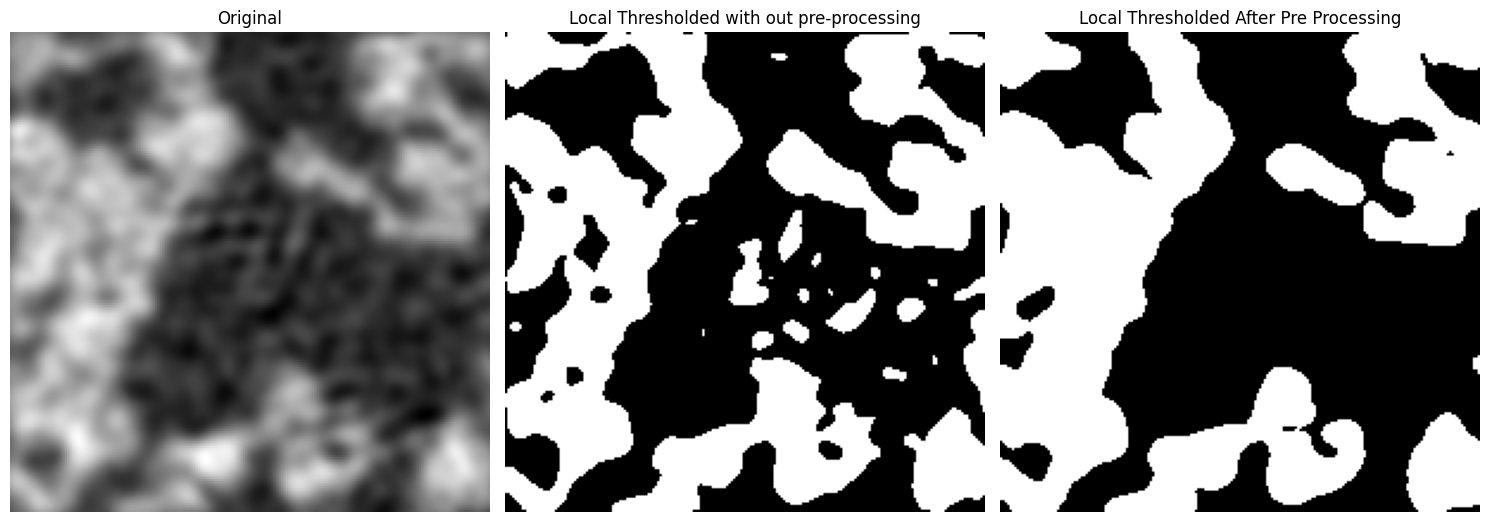

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.filters import threshold_local
from skimage import io  # or use your cosmo_1

# Assuming cosmo_1 is your 2D image from a z-slice
# Make sure it's float type for proper thresholding
image1 = cosmo_1.astype(float)
unsharp1 = sharpened1.astype(float)

# Set block size for local thresholding (must be odd)
block_size = 121  # you can also use it with values like 31, 51, 101
offset = 0  # adjust if needed to shift the threshold

# Compute the local threshold map
local_thresh = threshold_local(image1, block_size, offset=offset)
local_thresh2 = threshold_local(unsharp1, block_size, offset=offset)

# Apply threshold: pixels > local threshold → foreground (True)
binary_local = image1 > local_thresh
binary_local21 = unsharp1 > local_thresh2
# Plot original and thresholded image
fig, ax = plt.subplots(1, 3, figsize=(15, 10))
plt.gray()

ax[0].imshow(image1)
ax[0].set_title("Original")

ax[1].imshow(binary_local)
ax[1].set_title("Local Thresholded with out pre-processing")

ax[2].imshow(binary_local21)
ax[2].set_title("Local Thresholded After Pre Processing")

for a in ax:
    a.axis('off')

plt.tight_layout()
plt.show()


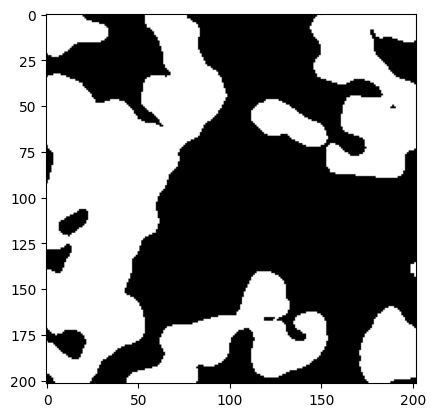

In [ ]:
plt.imshow(binary_local21)

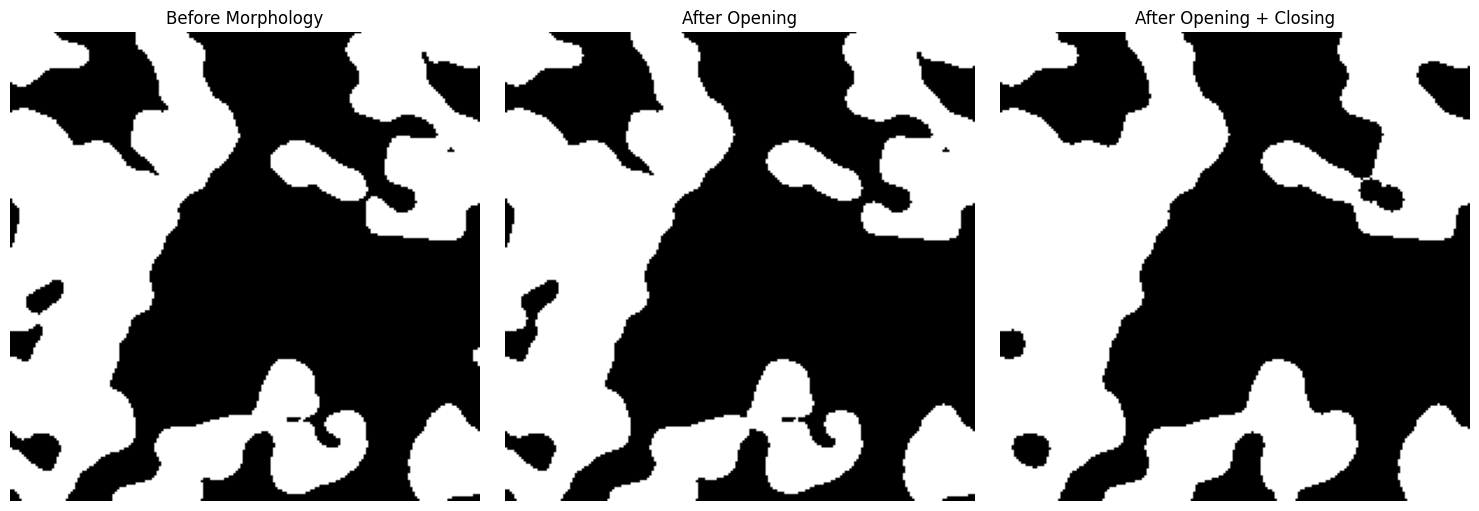

In [ ]:

from skimage.morphology import opening, closing, disk
import matplotlib.pyplot as plt
# Define structuring element size
selem = disk(5)  # Change the radius as needed, like 1, 3, 5, etc.

# Opening: removes small white noise
opened = opening(binary_local21, selem)

# Closing: fills small black holes inside regions
closed = closing(opened, selem)

fig, ax = plt.subplots(1, 3, figsize=(15, 5))
ax[0].imshow(binary_local21, cmap='gray')
ax[0].set_title('Before Morphology')

ax[1].imshow(opened, cmap='gray')
ax[1].set_title('After Opening')

ax[2].imshow(closed, cmap='gray')
ax[2].set_title('After Opening + Closing')

for a in ax:
    a.axis('off')

plt.tight_layout()
plt.show()


### Unsharp masking
Enhance local edges by adding a scaled high-frequency residual to a smoothed image. Inspect the `radius` and `amount` settings because sharpening can amplify noise and create halos.


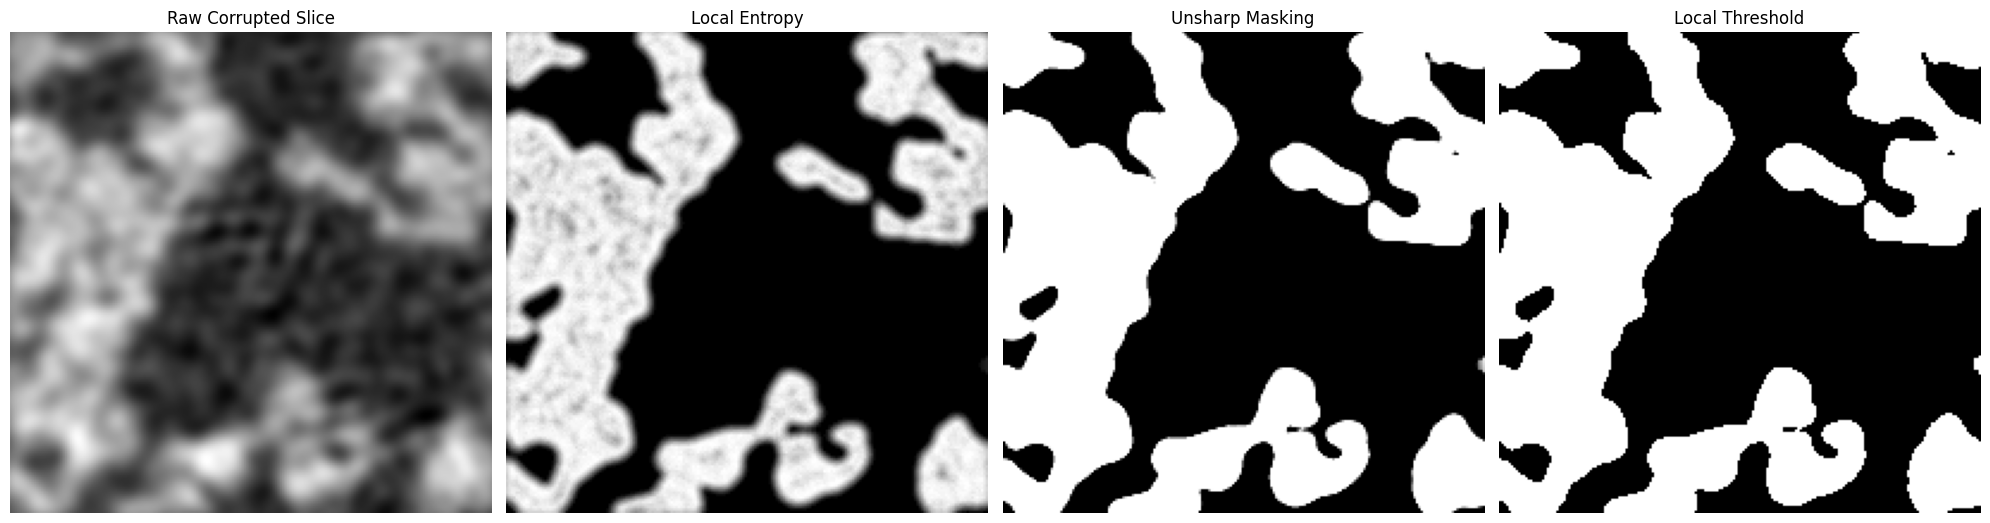

In [ ]:
fig, ax = plt.subplots(1, 4, figsize=(20, 10))

ax[0].imshow(cosmo_1, cmap='gray')
ax[0].set_title('Raw Corrupted Slice')

ax[1].imshow(entropy_map1, cmap='gray')
ax[1].set_title('Local Entropy')

ax[2].imshow(sharpened1, cmap='gray')
ax[2].set_title('Unsharp Masking')

ax[3].imshow(binary_local21, cmap='gray')
ax[3].set_title('Local Threshold')


for a in ax:
    a.axis('off')

plt.tight_layout()
plt.show()


### Unsharp masking
Enhance local edges by adding a scaled high-frequency residual to a smoothed image. Inspect the `radius` and `amount` settings because sharpening can amplify noise and create halos.


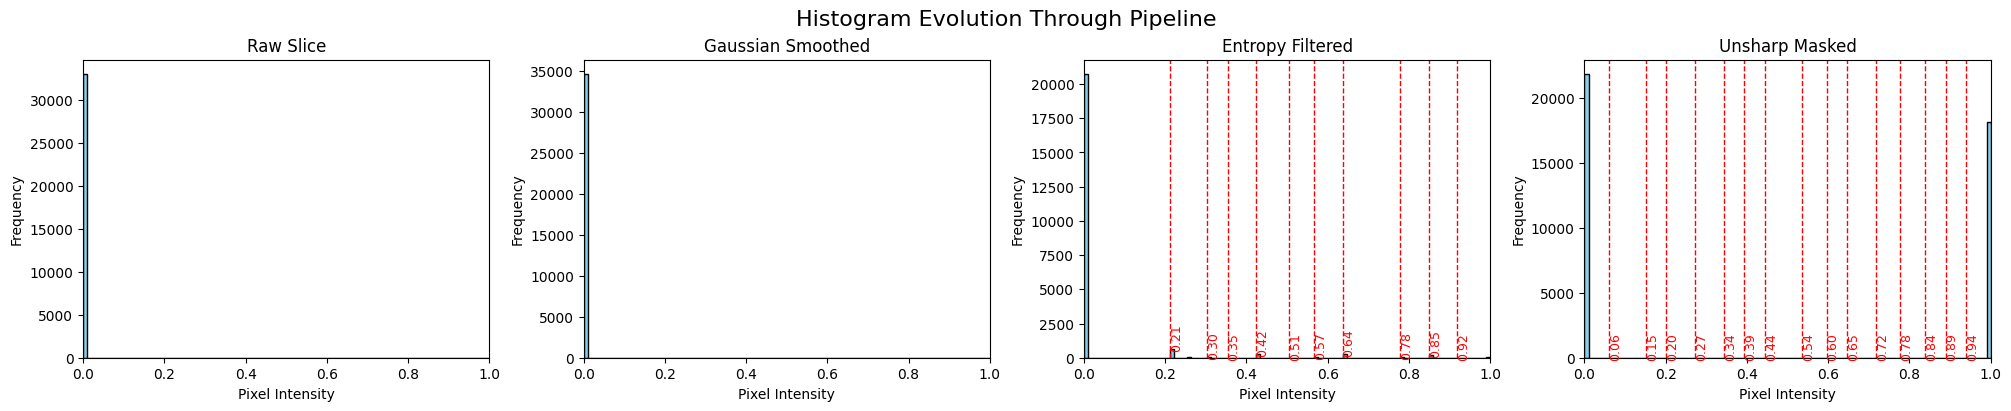

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import find_peaks

# Assuming the following variables are already defined:
# cosmo1         → raw slice
# smoothed_image → after Gaussian
# entropy_map_2  → after entropy filtering
# sharpened_1    → after unsharp masking

# Create a list of images and labels
images = [cosmo_1, smoothed_image, entropy_map2, sharpened1]
titles = ['Raw Slice', 'Gaussian Smoothed', 'Entropy Filtered', 'Unsharp Masked']

# Plot settings
fig, axes = plt.subplots(1, 4, figsize=(20, 4), constrained_layout=True)
bins = np.linspace(0, 1, 100)  # adjust range if your values are different

for ax, img, title in zip(axes, images, titles):
    # Flatten image to 1D
    pixels = img.flatten()

    # Plot histogram
    counts, bins_, _ = ax.hist(pixels, bins=bins, color='skyblue', edgecolor='k')
    ax.set_title(title, fontsize=12)
    ax.set_xlabel("Pixel Intensity")
    ax.set_ylabel("Frequency")
    ax.set_xlim(0, 1)

    # Find and mark peaks
    peak_indices, _ = find_peaks(counts, distance=5)
    for idx in peak_indices:
        peak_x = bins_[idx]
        ax.axvline(x=peak_x, color='red', linestyle='--', linewidth=1)
        ax.text(peak_x, counts[idx] + 50, f'{peak_x:.2f}', color='red', fontsize=9, rotation=90)

plt.suptitle("Histogram Evolution Through Pipeline", fontsize=16)
plt.show()


### Gaussian smoothing
Apply Gaussian convolution to suppress small-scale fluctuations. The `sigma` parameter controls the smoothing scale; stronger smoothing can also erase genuine small structures.


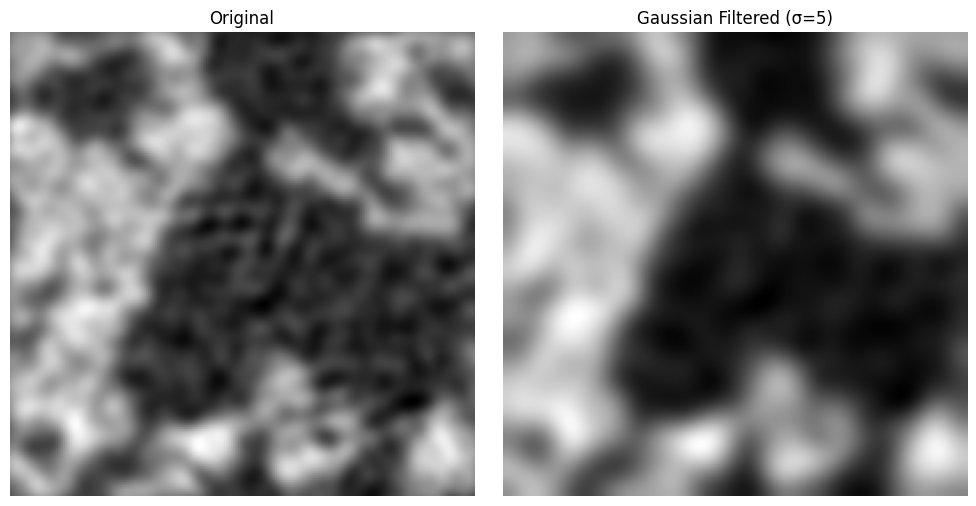

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from skimage import data, img_as_float

# Load a sample image (you can replace this with your own image)
image = cosmo_1  # grayscale image

# Apply Gaussian filter
sigma = 5  # standard deviation, controls amount of blur
smoothed_image = gaussian_filter(image, sigma=sigma)

# Display
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
axes[0].imshow(image, cmap='grey')
axes[0].set_title("Original")
axes[1].imshow(smoothed_image, cmap='grey')
axes[1].set_title(f"Gaussian Filtered (σ={sigma})")

for ax in axes:
    ax.axis('off')
plt.savefig("Image LT.png", dpi=600, bbox_inches='tight')
plt.tight_layout()
plt.show()


### Local entropy enhancement
Calculate neighbourhood entropy using a disk-shaped footprint. This measures local texture/variation, not ionization directly; intensity rescaling and footprint radius affect the result.


In [ ]:
Image1 = smoothed_image  # Dummy brightness temperature map

# --- 2. Apply Local Entropy ---
entropy_input = img_as_ubyte(exposure.rescale_intensity(cosmo_1))
entropy_map2 = entropy(entropy_input, morphology.disk(3))


### Fourier-domain filtering
Transform the image to Fourier space, apply a low-pass mask, and transform back. The cutoff/radius determines which spatial frequencies are retained; document it as a filtering choice, not guaranteed foreground removal.


In [ ]:
#FFT FOR ENTROPY

import numpy as np
import matplotlib.pyplot as plt
from scipy.fft import fft2, ifft2, fftshift, ifftshift
from skimage.util import invert
from skimage.exposure import rescale_intensity

def fft_low_pass_filter(entropy_map2, radius=20):
    # Step 1: Forward 2D FFT
    f_image = fft2(entropy_map2)
    f_shift = fftshift(f_image)  # Shift zero-freq to center

    # Step 2: Create circular low-pass filter mask
    rows, cols = image.shape
    crow, ccol = rows // 2, cols // 2
    y, x = np.ogrid[:rows, :cols]
    mask_area = (x - ccol)**2 + (y - crow)**2 <= radius**2
    mask = np.zeros_like(entropy_map2)
    mask[mask_area] = 1

    # Step 3: Apply mask
    f_filtered = f_shift * mask

    # Step 4: Inverse FFT to get denoised image
    f_ishift = ifftshift(f_filtered)
    denoised = np.abs(ifft2(f_ishift))

    return denoised, f_shift, f_filtered

# ---- Step 1: Apply FFT Filter ----
denoised_img, fft_original, fft_filtered = fft_low_pass_filter(entropy_map2, radius=5)

# ---- Step 2: Normalize and Invert ----
denoised_img_normE2 = rescale_intensity(denoised_img, in_range='image', out_range=(0, 1))
inverted_imgE2 = invert(denoised_img_normE2)

# ---- Step 3: Plot All Results ----
plt.figure(figsize=(16, 5))

plt.subplot(1, 3, 1)
plt.imshow(entropy_map2, cmap='gray')
plt.title("Entropy")
plt.axis('off')

plt.subplot(1, 3, 2)
plt.imshow(np.log(1 + np.abs(fft_original)), cmap='magma')
plt.title("FFT Spectrum (Original)")
plt.axis('off')

plt.subplot(1, 3, 3)
plt.imshow(denoised_img_normE2, cmap='gray')
plt.title("Denoised (Normalized)")
plt.axis('off')



plt.title("Inverted (Ionized = Dark)")
plt.axis('off')

plt.tight_layout()
plt.show()


### Local/adaptive thresholding
Compute a spatially varying threshold using a neighbourhood window. Check that `block_size` is odd and appropriate for the image dimensions, and record the offset because it changes the classified area.


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from skimage.filters import threshold_local
from skimage import io  # or use your cosmo_1

# Assuming cosmo_1 is your 2D image from a z-slice
# Make sure it's float type for proper thresholding
image3 = denoised_img_normE2.astype(float)


# Set block size for local thresholding (must be odd)
block_size = 501 # you can experiment with values like 31, 51, 101
offset = 0  # adjust if needed to shift the threshold

# Compute the local threshold map
local_thresh = threshold_local( denoised_img_normE2, block_size, offset=offset)


# Apply threshold: pixels > local threshold → foreground (True)
binary_local = denoised_img_normE2 > local_thresh

# Plot original and thresholded image
fig, ax = plt.subplots(1, 2, figsize=(10, 5))
plt.gray()

ax[0].imshow(denoised_img_normE2 , cmap='gray')
ax[0].set_title("Original")

ax[1].imshow(binary_local)
ax[1].set_title("Local Thresholded")

for a in ax:
    a.axis('off')

plt.tight_layout()
plt.show()


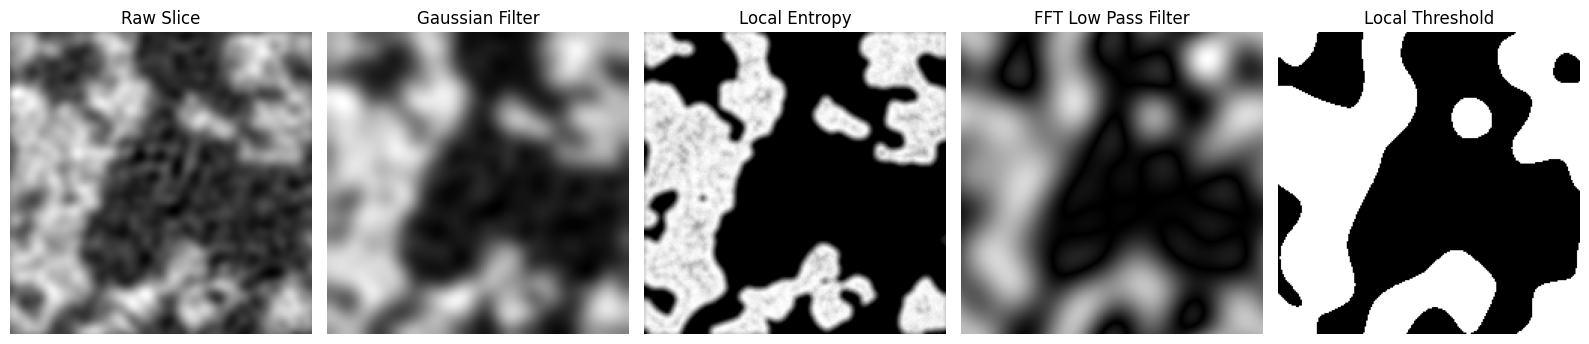

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(16, 9))
ax = axes.ravel()

ax[0].imshow(cosmo_1, cmap='gray')
ax[0].set_title("Raw Slice")
ax[0].axis('off')

ax[1].imshow(smoothed_image, cmap='gray')
ax[1].set_title("Gaussian Filter")
ax[1].axis('off')

ax[2].imshow(entropy_map2, cmap='gray')
ax[2].set_title("Local Entropy")
ax[2].axis('off')

ax[3].imshow(denoised_img_normE2, cmap='gray')
ax[3].set_title("FFT Low Pass Filter")
ax[3].axis('off')

ax[4].imshow(binary_local, cmap='gray')
ax[4].set_title("Local Threshold")
ax[4].axis('off')



plt.tight_layout()
plt.show()

<function matplotlib.pyplot.show(close=None, block=None)>

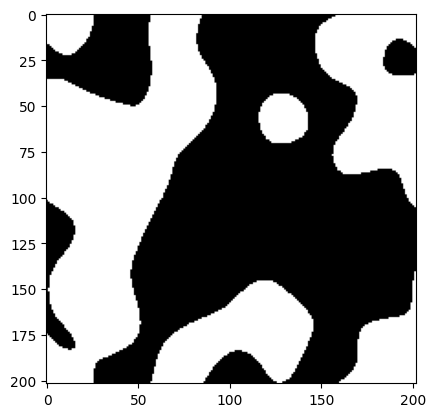

In [ ]:
plt.imshow(binary_local, cmap='grey')
plt.show

### Histogram diagnostics
Compare pixel-value distributions before and after processing. Histograms describe intensity distributions; by themselves they do not validate physical recovery of H II regions.


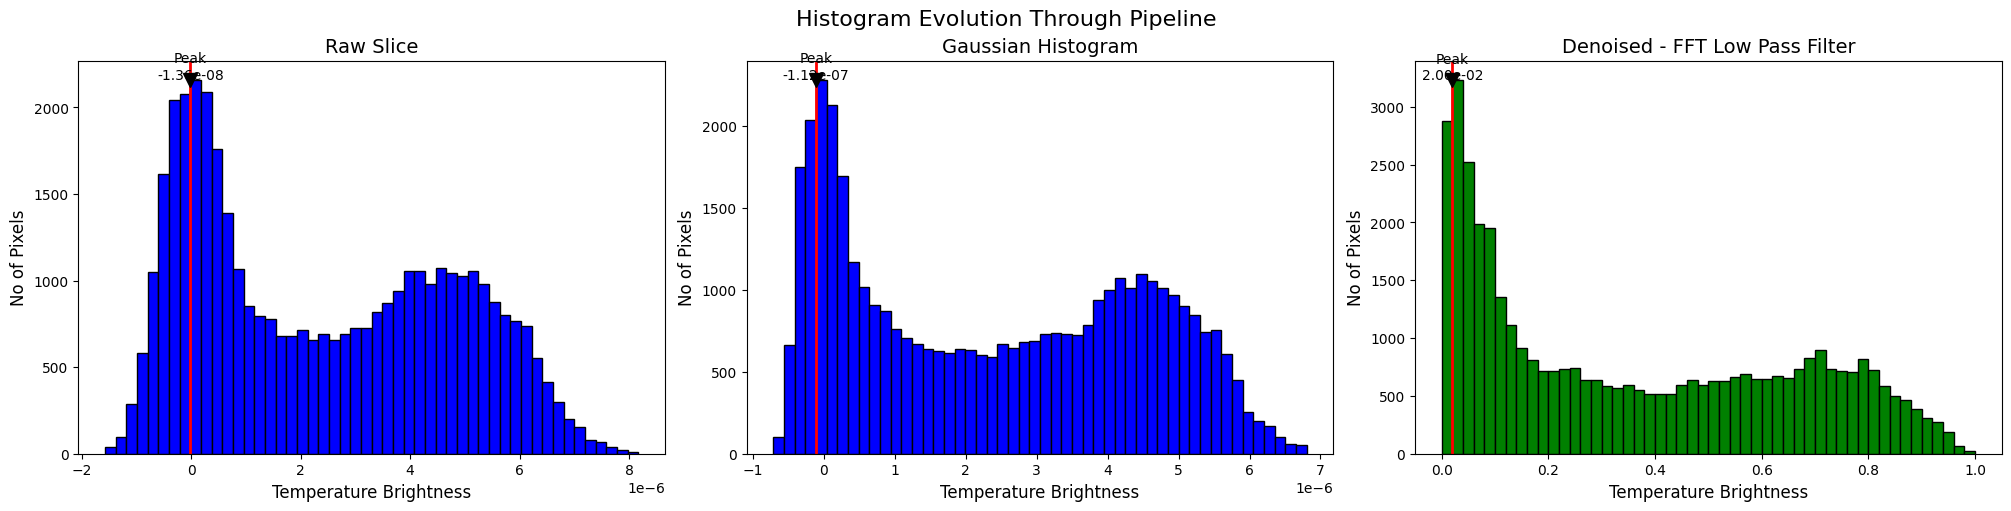

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import find_peaks

# === INPUT DATA ===
images = [cosmo_1, smoothed_image, denoised_img_normE2]
titles = ['Raw Slice', 'Gaussian Histogram', 'Denoised - FFT Low Pass Filter']
colors = ['blue', 'blue', 'green', 'blue']

# === PLOT ===
fig, axes = plt.subplots(1, 3, figsize=(20, 5), constrained_layout=True)

for ax, img, title, color in zip(axes, images, titles, colors):
    pixels = img.flatten()

    # Plot histogram
    counts, bins_, _ = ax.hist(pixels, bins=50, color=color, edgecolor='black')
    ax.set_title(title, fontsize=14)
    ax.set_xlabel("Temperature Brightness", fontsize=12)
    ax.set_ylabel("No of Pixels", fontsize=12)

    # Peak detection
    peak_idx = np.argmax(counts)
    peak_val = bins_[peak_idx]

    # Plot red ▼ at peak
    ax.axvline(peak_val, color='red', linewidth=2)
    ax.plot(peak_val, counts[peak_idx], 'v', color='black', markersize=10)
    ax.text(peak_val, counts[peak_idx] + 5, f"Peak\n{peak_val:.2e}", color='black',
            ha='center', fontsize=10)

plt.suptitle("Histogram Evolution Through Pipeline", fontsize=16)
plt.show()


### Histogram diagnostics
Compare pixel-value distributions before and after processing. Histograms describe intensity distributions; by themselves they do not validate physical recovery of H II regions.


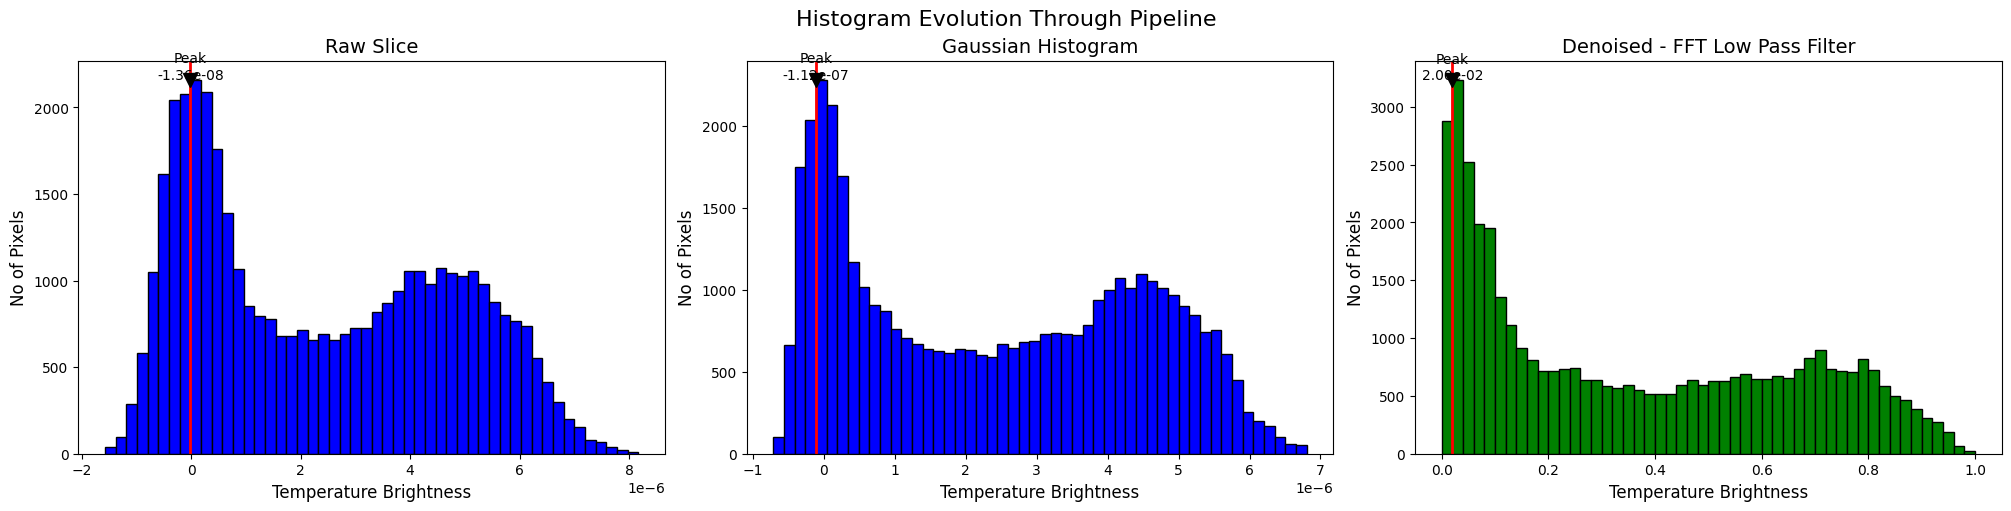

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from scipy.signal import find_peaks

# === INPUT DATA ===
images = [cosmo_1, smoothed_image, denoised_img_normE2]
titles = ['Raw Slice', 'Gaussian Histogram', 'Denoised - FFT Low Pass Filter']
colors = ['blue', 'blue', 'green', 'blue']

# === PLOT ===
fig, axes = plt.subplots(1, 3, figsize=(20, 5), constrained_layout=True)

for ax, img, title, color in zip(axes, images, titles, colors):
    pixels = img.flatten()

    # Plot histogram
    counts, bins_, _ = ax.hist(pixels, bins=50, color=color, edgecolor='black')
    ax.set_title(title, fontsize=14)
    ax.set_xlabel("Temperature Brightness", fontsize=12)
    ax.set_ylabel("No of Pixels", fontsize=12)

    # Peak detection
    peak_idx = np.argmax(counts)
    peak_val = bins_[peak_idx]

    # Plot red ▼ at peak
    ax.axvline(peak_val, color='red', linewidth=2)
    ax.plot(peak_val, counts[peak_idx], 'v', color='black', markersize=10)
    ax.text(peak_val, counts[peak_idx] + 5, f"Peak\n{peak_val:.2e}", color='black',
            ha='center', fontsize=10)

plt.suptitle("Histogram Evolution Through Pipeline", fontsize=16)
plt.show()


### Watershed / region-based segmentation
Use the binary mask and distance/topographic representation to assign region labels. Verify foreground polarity explicitly: the mask supplied to watershed must represent the structures intended for partitioning. This experiment is retained even where results are limited.


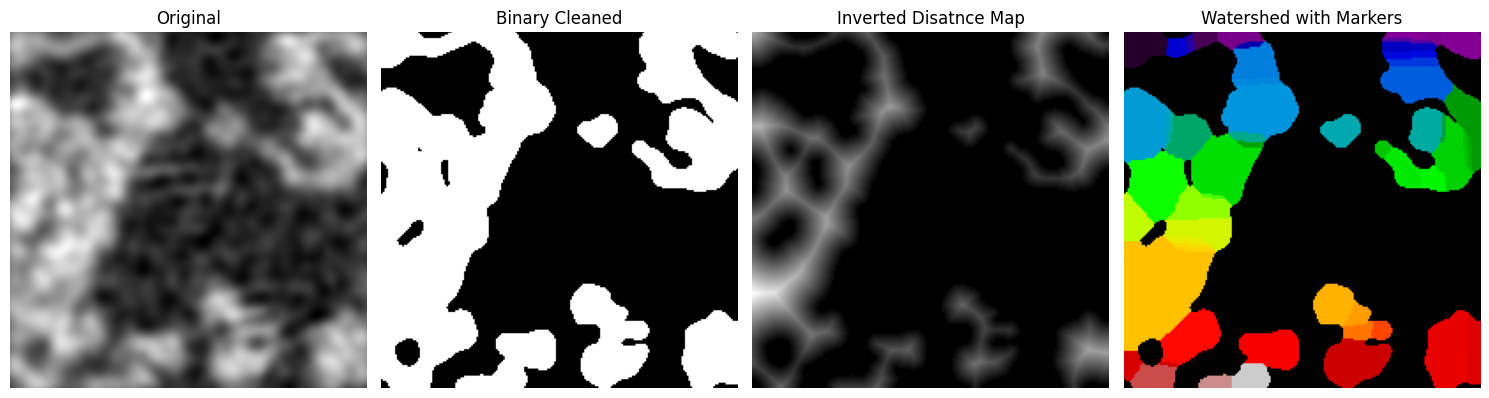

In [ ]:
from skimage.segmentation import watershed
from skimage.feature import peak_local_max
from skimage.morphology import remove_small_objects, local_maxima
from skimage.measure import label
from scipy import ndimage as ndi
import matplotlib.pyplot as plt

# Step 1: Clean binary mask
binary_clean = remove_small_objects(sharpened1.astype(bool), min_size=50)

# Step 2: Distance transform
distance = ndi.distance_transform_edt(binary_clean)

# Step 3: Local maxima mask
local_maxi = local_maxima(distance * binary_clean)

# Step 4: Label foreground markers
markers = label(local_maxi)

# Step 5: Apply watershed
labels_ws = watershed(-distance, markers, mask=binary_clean)

# Step 6: Display results
fig, ax = plt.subplots(1, 4, figsize=(15, 5))
ax[0].imshow(cosmo_1, cmap='gray')
ax[0].set_title('Original')

ax[1].imshow(binary_clean, cmap='gray')
ax[1].set_title('Binary Cleaned')

ax[2].imshow(distance, cmap='gray')
ax[2].set_title('Inverted Disatnce Map')


ax[3].imshow(labels_ws, cmap='nipy_spectral')
ax[3].set_title('Watershed with Markers')

for a in ax:
    a.set_axis_off()

plt.tight_layout()
plt.show()


In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# Load images from files
raw_images = [mpimg.imread('raw11.png'), mpimg.imread('raw12.png'),
              mpimg.imread('raw13.png'), mpimg.imread('raw14.png'),
              mpimg.imread('raw15.png'), mpimg.imread('raw16.png')]

seg_images = [mpimg.imread('seg11.png'), mpimg.imread('seg12.png'),
              mpimg.imread('seg13.png'), mpimg.imread('seg14.png'),
              mpimg.imread('seg15.png'), mpimg.imread('seg16.png')]

# Plot
fig, axs = plt.subplots(2, 6, figsize=(18, 6))

# First row: Raw images
for i in range(6):
    axs[0, i].imshow(raw_images[i], cmap='gray')
    axs[0, i].set_title(f'Raw {i+1}')
    axs[0, i].axis('off')

# Second row: Segmented images
for i in range(6):
    axs[1, i].imshow(seg_images[i], cmap='gray')
    axs[1, i].set_title(f'Seg {i+1}')
    axs[1, i].axis('off')

plt.tight_layout()
plt.show()


FileNotFoundError: [Errno 2] No such file or directory: 'raw11.png'

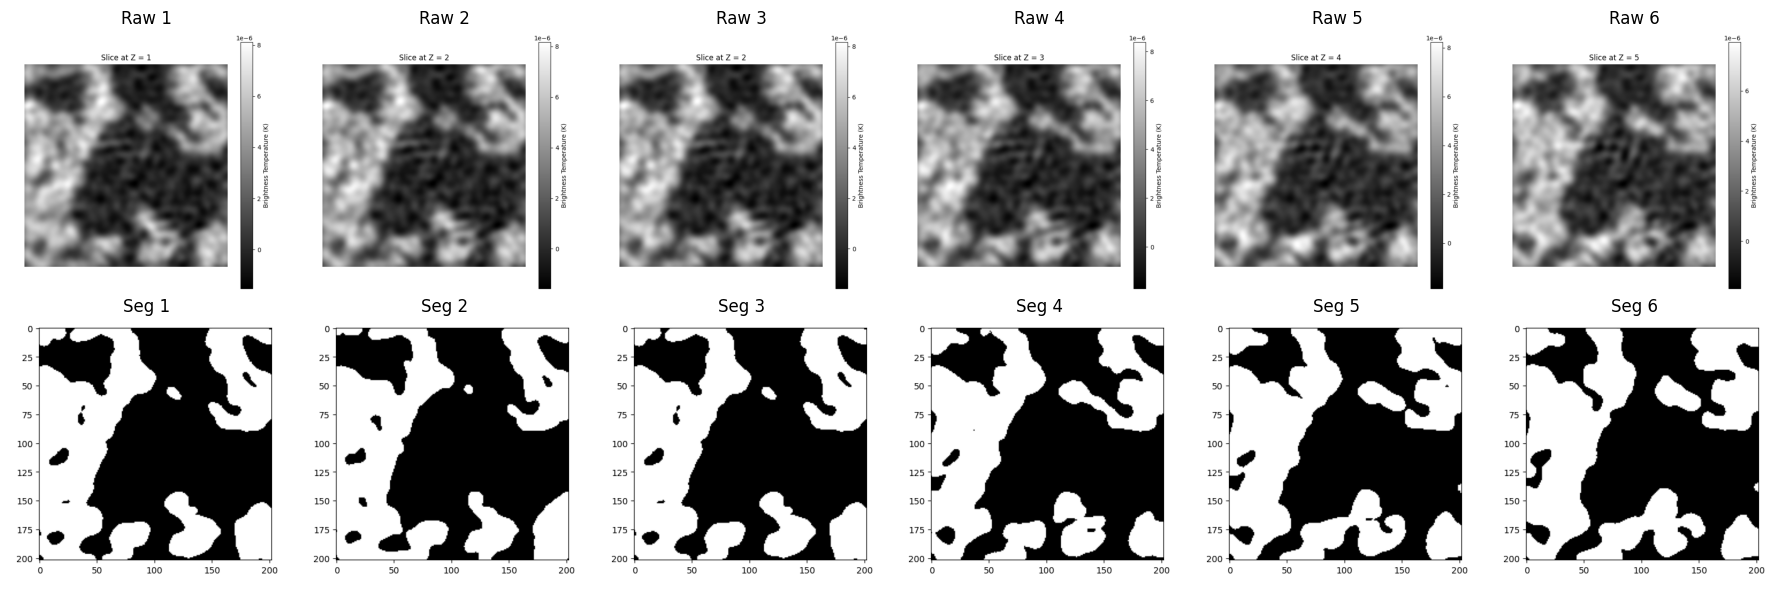

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

# Load images from files
raw_images = [mpimg.imread('raw1.png'), mpimg.imread('raw2.png'),
              mpimg.imread('raw3.png'), mpimg.imread('raw4.png'),
              mpimg.imread('raw5.png'), mpimg.imread('raw6.png')]

seg_images = [mpimg.imread('seg1.png'), mpimg.imread('seg2.png'),
              mpimg.imread('seg3.png'), mpimg.imread('seg4.png'),
              mpimg.imread('seg5.png'), mpimg.imread('seg6.png')]

# Plot
fig, axs = plt.subplots(2, 6, figsize=(18, 6))

# First row: Raw images
for i in range(6):
    axs[0, i].imshow(raw_images[i], cmap='gray')
    axs[0, i].set_title(f'Raw {i+1}')
    axs[0, i].axis('off')

# Second row: Segmented images
for i in range(6):
    axs[1, i].imshow(seg_images[i], cmap='gray')
    axs[1, i].set_title(f'Seg {i+1}')
    axs[1, i].axis('off')

plt.tight_layout()
plt.show()
